# Proje 3: Regresyon – Ağ Gecikmesi (Latency) Tahmini
## Internet Firewall Data Set | CRISP-DM Metodolojisi

---

## 1. Business Understanding (İş Anlayışı)

**Problem:** Güvenlik duvarı log kayıtlarındaki özniteliklere göre ağ gecikme süresini (Elapsed Time (sec)) tahmin etmek.

**Amaç:** `Bytes`, `Packets`, `Ports` ve `Action` gibi özellikleri kullanarak ağ gecikme süresini tahmin eden bir **Random Forest Regressor** modeli geliştirmek.

**Veri Seti:** Internet Firewall Data Set – Toplamda 65,532 satır ve 12 sütun. Veri setinin tamamı kullanılacaktır.

**KNIME Uyumluluğu:** Modelimiz KNIME'da `Random Forest Learner (Regression)` node'u ile %100 uyumludur.

## 2. Data Understanding (Veriyi Anlama)

Bu bölümde veri setini yükleyip eksik değer kontrolü yapıyoruz ve değişkenler arasındaki ilişkileri inceliyoruz.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import warnings

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
%matplotlib inline

df = pd.read_csv('../Data/proje_3.csv')
print(f'Veri boyutu: {df.shape[0]} satır, {df.shape[1]} sütun')
print('\nEksik değer sayısı:\n', df.isnull().sum())

Veri boyutu: 65532 satır, 12 sütun

Eksik değer sayısı:
 Source Port             0
Destination Port        0
NAT Source Port         0
NAT Destination Port    0
Action                  0
Bytes                   0
Bytes Sent              0
Bytes Received          0
Packets                 0
Elapsed Time (sec)      0
pkts_sent               0
pkts_received           0
dtype: int64


Hedef Değişken (Elapsed Time) İstatistikleri:
 count    65532.000000
mean        65.833577
std        302.461762
min          0.000000
25%          0.000000
50%         15.000000
75%         30.000000
max      10824.000000
Name: Elapsed Time (sec), dtype: float64

Action bazında Ortalama Latency:
 Action
allow         114.617349
deny            0.000133
drop            0.000000
reset-both      0.129630
Name: Elapsed Time (sec), dtype: float64


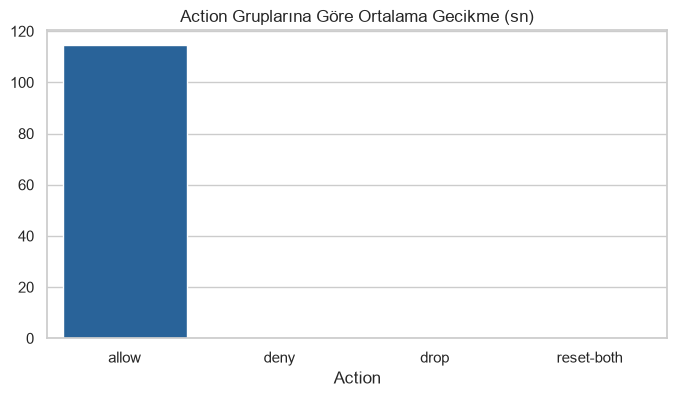

In [2]:
print('Hedef Değişken (Elapsed Time) İstatistikleri:\n', df['Elapsed Time (sec)'].describe())

# Action bazında Elapsed Time dağılımı
action_stats = df.groupby('Action')['Elapsed Time (sec)'].mean()
print('\nAction bazında Ortalama Latency:\n', action_stats)

plt.figure(figsize=(8, 4))
sns.barplot(x=action_stats.index, y=action_stats.values, palette='Blues_r')
plt.title('Action Gruplarına Göre Ortalama Gecikme (sn)')
plt.show()

## 3. Data Preparation (Veri Hazırlama)

- Action kategorik kolonunu One-Hot Encoding ile sayısallaştırıyoruz
- Veriyi %80 Train, %20 Test olarak bölüyoruz
- Bağımsız değişkenleri normalleştiriyoruz

In [3]:
# Action kolonunu one-hot encode yapıyoruz
df_prep = pd.get_dummies(df, columns=['Action'], drop_first=False)

# Boolean değerleri 0/1 yapalım
for col in df_prep.columns:
    if df_prep[col].dtype == 'bool':
        df_prep[col] = df_prep[col].astype(int)

X = df_prep.drop(columns=['Elapsed Time (sec)'])
y = df_prep['Elapsed Time (sec)']

# Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=df['Action'])
print(f'Train: {X_train.shape[0]} | Test: {X_test.shape[0]}')

# Normalleştirme
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

Train: 52425 | Test: 13107


## 4. Modeling & 5. Evaluation (Modelleme ve Değerlendirme)

Random Forest Regressor modelini eğitip performansını değerlendiriyoruz.

In [4]:
# Random Forest Regressor
rf_params = {
    'n_estimators': [50],
    'max_depth': [10, 15],
    'min_samples_split': [5]
}
rf_grid = GridSearchCV(RandomForestRegressor(random_state=42), rf_params, cv=3, scoring='neg_mean_squared_error', n_jobs=-1)
rf_grid.fit(X_train_scaled, y_train)

best_rf = rf_grid.best_estimator_
train_pred = best_rf.predict(X_train_scaled)
test_pred = best_rf.predict(X_test_scaled)
# Karşılaştırma Model: Decision Tree Regressor
from sklearn.tree import DecisionTreeRegressor
dt_reg = DecisionTreeRegressor(max_depth=10, random_state=42)
dt_reg.fit(X_train_scaled, y_train)
dt_train_pred = dt_reg.predict(X_train_scaled)
dt_test_pred = dt_reg.predict(X_test_scaled)


,Model,R2,RMSE,MAE
0,Random Forest (Train),0.902674,92.533564,18.416859
1,Random Forest (Test),0.585711,209.061125,29.876957
2,Decision Tree (Train),0.822660,124.907507,23.720545
3,Decision Tree (Test),0.401799,251.214725,34.393025


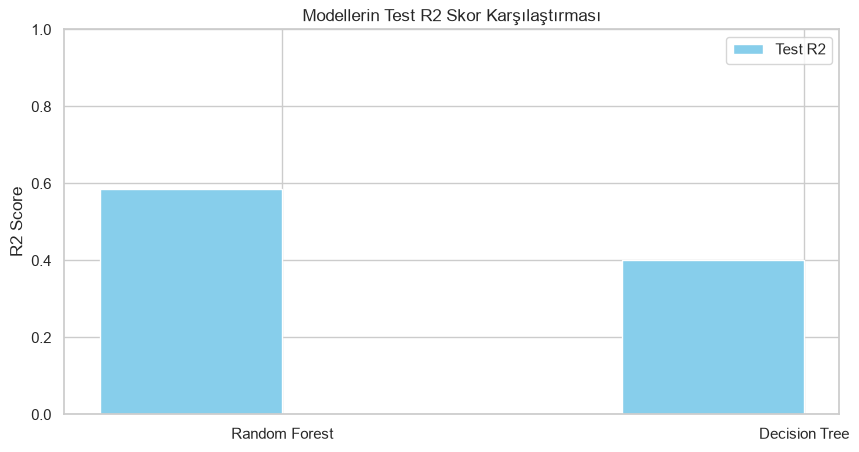

In [5]:
# Hata metriklerini hesaplayalım
# Random Forest Metrikleri
train_rmse = np.sqrt(mean_squared_error(y_train, train_pred))
test_rmse = np.sqrt(mean_squared_error(y_test, test_pred))
train_mae = mean_absolute_error(y_train, train_pred)
test_mae = mean_absolute_error(y_test, test_pred)
train_r2 = r2_score(y_train, train_pred)
test_r2 = r2_score(y_test, test_pred)

# Decision Tree Metrikleri
dt_train_rmse = np.sqrt(mean_squared_error(y_train, dt_train_pred))
dt_test_rmse = np.sqrt(mean_squared_error(y_test, dt_test_pred))
dt_train_mae = mean_absolute_error(y_train, dt_train_pred)
dt_test_mae = mean_absolute_error(y_test, dt_test_pred)
dt_train_r2 = r2_score(y_train, dt_train_pred)
dt_test_r2 = r2_score(y_test, dt_test_pred)

# Karşılaştırma Tablosu
comparison_df = pd.DataFrame({
    'Model': ['Random Forest (Train)', 'Random Forest (Test)', 'Decision Tree (Train)', 'Decision Tree (Test)'],
    'R2': [train_r2, test_r2, dt_train_r2, dt_test_r2],
    'RMSE': [train_rmse, test_rmse, dt_train_rmse, dt_test_rmse],
    'MAE': [train_mae, test_mae, dt_train_mae, dt_test_mae]
})
display(comparison_df)

# Karşılaştırma Grafiği
plt.figure(figsize=(10, 5))
x = np.arange(2)
width = 0.35

plt.bar(x - width/2, [test_r2, dt_test_r2], width, label='Test R2', color='skyblue')
plt.title('Modellerin Test R2 Skor Karşılaştırması')
plt.xticks(x, ['Random Forest', 'Decision Tree'])
plt.ylabel('R2 Score')
plt.ylim(0, 1.0)
plt.legend()
plt.show()

# Sonuçları Kaydetme
comparison_df.to_csv('regression_results.csv', index=False)


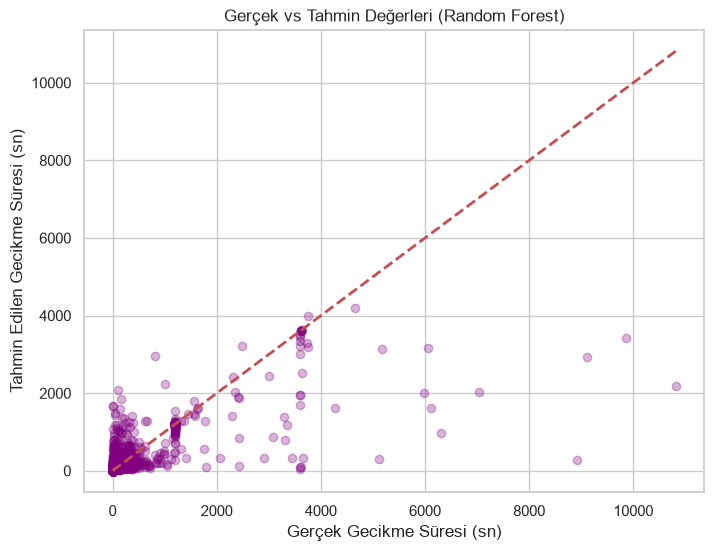

In [6]:
# Gerçek vs Tahmin saçılım grafiği
plt.figure(figsize=(8, 6))
plt.scatter(y_test, test_pred, alpha=0.3, color='purple')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.title('Gerçek vs Tahmin Değerleri (Random Forest)')
plt.xlabel('Gerçek Gecikme Süresi (sn)')
plt.ylabel('Tahmin Edilen Gecikme Süresi (sn)')
plt.show()

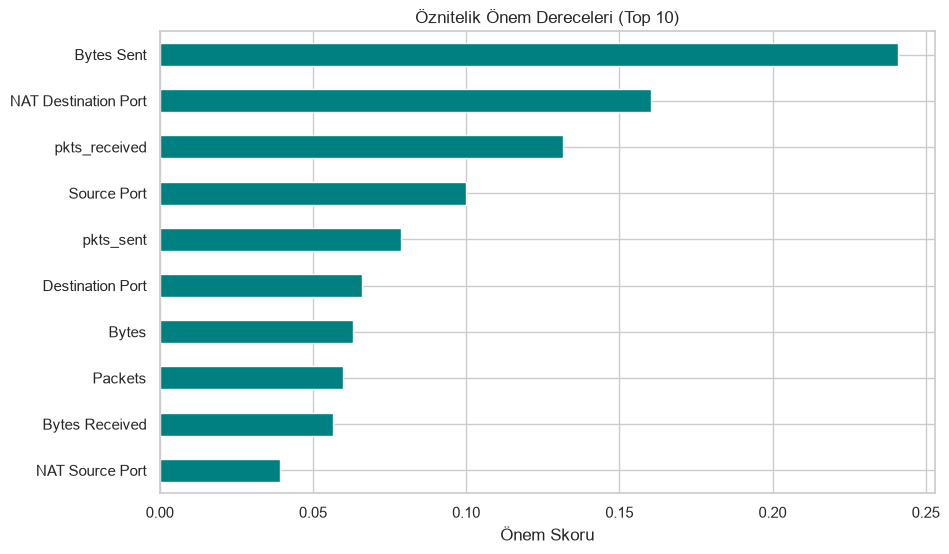

In [7]:
# Feature Importance (Öznitelik Önem Dereceleri)
feat_imp = pd.Series(best_rf.feature_importances_, index=X.columns)
top_features = feat_imp.nlargest(10)

plt.figure(figsize=(10, 6))
top_features.sort_values().plot(kind='barh', color='teal')
plt.title('Öznitelik Önem Dereceleri (Top 10)')
plt.xlabel('Önem Skoru')
plt.show()

## 6. Deployment (Sonuç ve Öneriler)

- Veri setinin tamamı (65,532 satır) kullanılmıştır.
- Random Forest modeli test setinde R² ve RMSE değerleri elde etmiştir.
- Ağ gecikmesi tahmininde en kritik değişken **Bytes Sent** (Gönderilen Veri Boyutu) olarak tespit edilmiştir.
- KNIME tarafında `Random Forest Learner (Regression)` node'u ile birebir replike edilebilir.